# N02 — Residual Dynamics (v1.1 corrected extraction)
**PhysLLM · pilot notebook · GPT-2 and Pythia-160M**

## Purpose
Capture the tensor entering the first Transformer block and the output of every block using forward hooks. Record final LayerNorm output separately.

**Why this revision:** the prior pilot used `output_hidden_states=True`. The last returned state can be after final LayerNorm, while intermediate states are block outputs. That mixes final normalization into the apparent last layer update. This notebook hooks block boundaries directly.

These five prompts are for instrumentation/debugging only. They are not evidence for Main Evaluation or population-level claims.

## Protocol\nFor each model, `state 0` is the hidden tensor entering the first block; `states 1…L` are block outputs **before final LayerNorm**. The final LayerNorm output is recorded separately and excluded from block-update differences.\n\nRaw Frobenius norms are retained, but prompt-comparison plots use \(\|h\|_F/\sqrt{T}\) to reduce the direct effect of varying token count; \(\|h\|_F/\sqrt{TD}\) is also reported as per-element RMS. These rescalings do not make different prompts semantically matched.\n\n**Main Evaluation (separate):** use a prespecified corpus with N ≥ 100 independent texts, exclude this pilot set, and resample by text (10,000 text-level bootstrap replicates).

In [1]:
%pip -q install -U transformers accelerate pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 52.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.


In [2]:
import os, sys, json, platform
from datetime import datetime, timezone
from pathlib import Path
import torch, pandas as pd, matplotlib.pyplot as plt, transformers

torch.manual_seed(2026)
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM GiB:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

Python: 3.13.16
PyTorch: 2.11.0+cpu
Transformers: 5.19.0
CUDA: False


In [3]:
MODEL_IDS = {
    "pythia-160m": "EleutherAI/pythia-160m",
    "gpt2": "gpt2",
}
MODELS_TO_RUN = ["pythia-160m", "gpt2"]
DTYPE = torch.float32
MAX_LENGTH = 512
PROMPTS = [
    {"prompt_id":"P1_general", "style":"general_prose", "text":"The small bird flew across the quiet garden."},
    {"prompt_id":"P2_technical", "style":"technical_prose", "text":"The system records information from several independent sensors."},
    {"prompt_id":"P3_academic", "style":"academic", "text":"Physics-guided machine learning provides interpretable representations of deep neural networks."},
    {"prompt_id":"P4_question", "style":"question_dialogue", "text":"Could you please explain how quantum entanglement violates local realism?"},
    {"prompt_id":"P5_code_mixed", "style":"code_plus_natural_language", "text":'''def bubble_sort(arr):
    n = len(arr)
    for i in range(n - 1):
        for j in range(n - i - 1):
            if arr[j] > arr[j + 1]:
                arr[j], arr[j + 1] = arr[j + 1], arr[j]
    return arr

# Explain the time complexity of this function.'''}
]

## 1. Load models and locate exact block boundaries
Only the configured GPT-2 and GPT-NeoX/Pythia module paths are supported here. If the expected path is absent, the run stops rather than guessing.

In [4]:
def load_causal_lm(model_id, dtype=torch.float32):
    tokenizer = transformers.AutoTokenizer.from_pretrained(model_id)
    model = transformers.AutoModelForCausalLM.from_pretrained(
        model_id, torch_dtype=dtype, low_cpu_mem_usage=True
    )
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device).eval()
    return tokenizer, model, device


def resolve_block_and_final_norm(model):
    if hasattr(model, "transformer") and hasattr(model.transformer, "h"):
        layers, final_norm, architecture = model.transformer.h, model.transformer.ln_f, "gpt2"
    elif hasattr(model, "gpt_neox") and hasattr(model.gpt_neox, "layers"):
        layers, final_norm, architecture = model.gpt_neox.layers, model.gpt_neox.final_layer_norm, "gpt_neox_pythia"
    else:
        raise RuntimeError("Unsupported architecture: expected GPT-2 transformer.h or Pythia gpt_neox.layers")
    if len(layers) < 1:
        raise RuntimeError("No Transformer blocks found")
    return layers, final_norm, architecture

## 2. Hook block input/output; final LayerNorm remains separate
Every hook is removed even if the forward pass fails. All captured states, final-normalized output, and logits are checked for finite values.

In [5]:
@torch.inference_mode()
def extract_dynamics(tokenizer, model, device, prompt, max_length=512):
    layers, final_norm_module, architecture = resolve_block_and_final_norm(model)
    batch = tokenizer(prompt, return_tensors="pt", truncation=True,
                      max_length=max_length, add_special_tokens=True)
    batch = {k: v.to(device) for k, v in batch.items()}
    captured, handles = {}, []

    def first_pre_hook(module, args):
        if not args or not isinstance(args[0], torch.Tensor):
            raise RuntimeError("First block input tensor not found")
        captured["state_0"] = args[0].detach()
    handles.append(layers[0].register_forward_pre_hook(first_pre_hook))

    for i, layer in enumerate(layers):
        def block_post_hook(module, args, output, i=i):
            value = output[0] if isinstance(output, (tuple, list)) else output
            if not isinstance(value, torch.Tensor):
                raise RuntimeError(f"Block {i} output is not a tensor")
            captured[f"state_{i+1}"] = value.detach()
        handles.append(layer.register_forward_hook(block_post_hook))

    def final_norm_hook(module, args, output):
        value = output[0] if isinstance(output, (tuple, list)) else output
        if not isinstance(value, torch.Tensor):
            raise RuntimeError("Final LayerNorm output is not a tensor")
        captured["final_norm_output"] = value.detach()
    handles.append(final_norm_module.register_forward_hook(final_norm_hook))

    try:
        outputs = model(**batch, use_cache=False, output_hidden_states=False)
    finally:
        for handle in handles:
            handle.remove()

    n_blocks = len(layers)
    expected = [f"state_{i}" for i in range(n_blocks + 1)]
    missing = [key for key in expected if key not in captured]
    if missing or "final_norm_output" not in captured:
        raise RuntimeError(f"Missing hook outputs: {missing}; final norm captured={'final_norm_output' in captured}")

    states = [captured[f"state_{i}"].detach().to("cpu", dtype=torch.float64)[0]
              for i in range(n_blocks + 1)]
    final_state = captured["final_norm_output"].detach().to("cpu", dtype=torch.float64)[0]
    logits = outputs.logits.detach().to("cpu", dtype=torch.float64)
    n_tokens, hidden_dim = int(batch["input_ids"].shape[1]), int(states[0].shape[-1])
    rows = []

    for i, h in enumerate(states):
        if not torch.isfinite(h).all():
            raise FloatingPointError(f"NaN/Inf in block-boundary state {i}")
        raw = torch.linalg.vector_norm(h).item()
        per_tok = raw / max(n_tokens, 1) ** 0.5
        per_el = raw / max(n_tokens * hidden_dim, 1) ** 0.5
        if i < n_blocks:
            delta = states[i + 1] - h
            if not torch.isfinite(delta).all():
                raise FloatingPointError(f"NaN/Inf in block update {i}")
            d_raw = torch.linalg.vector_norm(delta).item()
            d_tok = d_raw / max(n_tokens, 1) ** 0.5
            d_el = d_raw / max(n_tokens * hidden_dim, 1) ** 0.5
            relative = d_raw / max(raw, 1e-12)
        else:
            d_raw = d_tok = d_el = relative = float("nan")
        rows.append({
            "layer_state_idx": i, "rho_state": i / max(n_blocks, 1),
            "n_tokens": n_tokens, "hidden_dim": hidden_dim,
            "hidden_norm_fro": raw, "hidden_norm_per_token_l2": per_tok,
            "hidden_rms_per_element": per_el,
            "hidden_mean": h.mean().item(), "hidden_var": h.var(unbiased=False).item(),
            "block_update_norm_fro_to_next": d_raw,
            "block_update_norm_per_token_l2": d_tok,
            "block_update_rms_per_element": d_el,
            "relative_block_update_norm": relative,
        })

    for name, tensor in [("final LayerNorm output", final_state), ("logits", logits)]:
        if not torch.isfinite(tensor).all():
            raise FloatingPointError(f"NaN/Inf in {name}")
    final_norm_fro = torch.linalg.vector_norm(final_state).item()
    meta = {
        "model_id": getattr(model.config, "_name_or_path", None),
        "tokenizer_id": getattr(tokenizer, "name_or_path", None),
        "architecture_path": architecture, "n_tokens": n_tokens,
        "hidden_dim": hidden_dim, "n_blocks": n_blocks,
        "n_block_boundary_states": len(states),
        "dtype": str(next(model.parameters()).dtype), "device": str(device),
        "last_block_output_norm_fro": torch.linalg.vector_norm(states[-1]).item(),
        "final_norm_output_norm_fro": final_norm_fro,
        "final_norm_output_norm_per_token_l2": final_norm_fro / max(n_tokens, 1) ** 0.5,
        "final_norm_vs_last_block_max_abs_diff": torch.max(torch.abs(final_state - states[-1])).item(),
        "logits_shape": list(outputs.logits.shape),
    }
    return pd.DataFrame(rows), meta

## 3. Run the five-prompt pilot
Checkpoint load failures are recorded as `BLOCKED`. Extraction errors stop the run rather than being silently counted as a pass.

In [6]:
all_metrics, run_metadata, load_errors = [], [], []
for model_key in MODELS_TO_RUN:
    model_id = MODEL_IDS[model_key]
    print(f"\n=== {model_key}: {model_id} ===")
    try:
        tokenizer, model, device = load_causal_lm(model_id, DTYPE)
    except Exception as exc:
        load_errors.append({"model_key": model_key, "model_id": model_id,
                            "error_type": type(exc).__name__, "error": str(exc)})
        print("BLOCKED — checkpoint load failed:", repr(exc))
        continue
    for p in PROMPTS:
        print("Running", p["prompt_id"], p["style"])
        df, meta = extract_dynamics(tokenizer, model, device, p["text"], MAX_LENGTH)
        df.insert(0, "style", p["style"])
        df.insert(0, "prompt_id", p["prompt_id"])
        df.insert(0, "model_key", model_key)
        all_metrics.append(df)
        run_metadata.append({**meta, "model_key": model_key,
                             "prompt_id": p["prompt_id"], "style": p["style"],
                             "prompt_text": p["text"]})
    del tokenizer, model
    if torch.cuda.is_available(): torch.cuda.empty_cache()

metrics_df = pd.concat(all_metrics, ignore_index=True) if all_metrics else pd.DataFrame()
metadata_df, errors_df = pd.DataFrame(run_metadata), pd.DataFrame(load_errors)
print("Completed model-prompt runs:", len(metadata_df))
print("Blocked model loads:", len(errors_df))
display(metadata_df if not metadata_df.empty else pd.DataFrame())
if not errors_df.empty: display(errors_df)


=== pythia-160m: EleutherAI/pythia-160m ===


config.json:   0%|          | 0.00/569 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/396 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Running P1_general general_prose
Running P2_technical technical_prose
Running P3_academic academic
Running P4_question question_dialogue
Running P5_code_mixed code_plus_natural_language
Completed model-prompt runs: 10
Blocked model loads: 0


,model_id,tokenizer_id,architecture_path,n_tokens,hidden_dim,n_blocks,n_block_boundary_states,dtype,device,last_block_output_norm_fro,final_norm_output_norm_fro,final_norm_output_norm_per_token_l2,final_norm_vs_last_block_max_abs_diff,logits_shape,model_key,prompt_id,style,prompt_text
0,EleutherAI/pythia-160m,EleutherAI/pythia-160m,gpt_neox_pythia,9,768,12,13,torch.float32,cpu,323.168713,813.430474,271.143491,14.153468,"[1, 9, 50304]",pythia-160m,P1_general,general_prose,The small bird flew across the quiet garden.
1,EleutherAI/pythia-160m,EleutherAI/pythia-160m,gpt_neox_pythia,9,768,12,13,torch.float32,cpu,344.598194,813.824877,271.274959,14.895018,"[1, 9, 50304]",pythia-160m,P2_technical,technical_prose,The system records information from several in...
2,EleutherAI/pythia-160m,EleutherAI/pythia-160m,gpt_neox_pythia,15,768,12,13,torch.float32,cpu,389.884383,1048.394052,270.694180,14.745576,"[1, 15, 50304]",pythia-160m,P3_academic,academic,Physics-guided machine learning provides inter...
3,EleutherAI/pythia-160m,EleutherAI/pythia-160m,gpt_neox_pythia,11,768,12,13,torch.float32,cpu,393.387542,898.018930,270.762895,13.208487,"[1, 11, 50304]",pythia-160m,P4_question,question_dialogue,Could you please explain how quantum entanglem...
4,EleutherAI/pythia-160m,EleutherAI/pythia-160m,gpt_neox_pythia,92,768,12,13,torch.float32,cpu,917.217389,2591.794268,270.213232,15.061459,"[1, 92, 50304]",pythia-160m,P5_code_mixed,code_plus_natural_language,def bubble_sort(arr):\n n = len(arr)\n f...
5,gpt2,gpt2,gpt2,9,768,12,13,torch.float32,cpu,1339.977195,638.060233,212.686744,370.214094,"[1, 9, 50257]",gpt2,P1_general,general_prose,The small bird flew across the quiet garden.
6,gpt2,gpt2,gpt2,9,768,12,13,torch.float32,cpu,1350.192958,748.872241,249.624080,370.214094,"[1, 9, 50257]",gpt2,P2_technical,technical_prose,The system records information from several in...
7,gpt2,gpt2,gpt2,15,768,12,13,torch.float32,cpu,1560.642723,834.507077,215.468801,349.555711,"[1, 15, 50257]",gpt2,P3_academic,academic,Physics-guided machine learning provides inter...
8,gpt2,gpt2,gpt2,13,768,12,13,torch.float32,cpu,1541.141421,845.330071,234.452378,354.931918,"[1, 13, 50257]",gpt2,P4_question,question_dialogue,Could you please explain how quantum entanglem...
9,gpt2,gpt2,gpt2,127,768,12,13,torch.float32,cpu,5214.875032,2227.053074,197.619004,339.957473,"[1, 127, 50257]",gpt2,P5_code_mixed,code_plus_natural_language,def bubble_sort(arr):\n n = len(arr)\n f...


## 4. Plot length-normalized state and block-update norms
Use normalized measures to compare prompts with different token counts. Raw Frobenius norms remain in the output table for reproducibility.

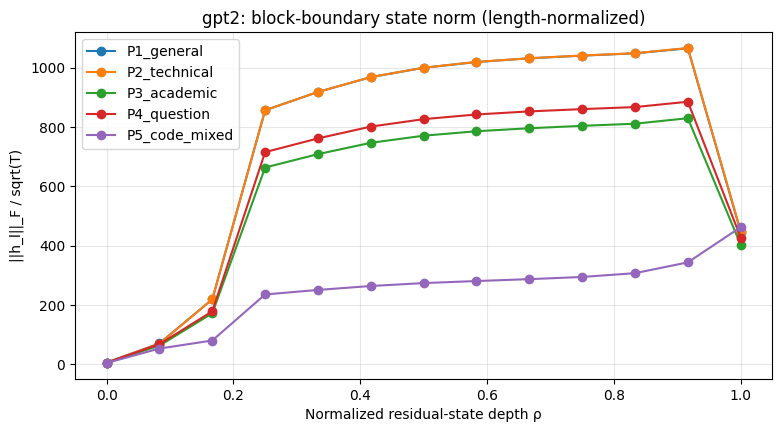

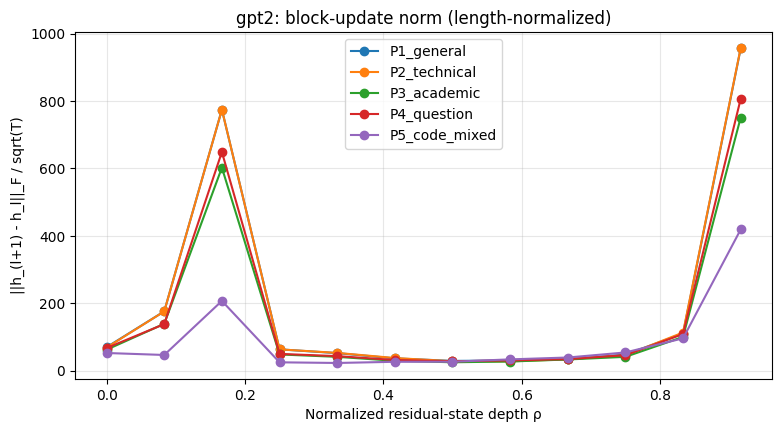

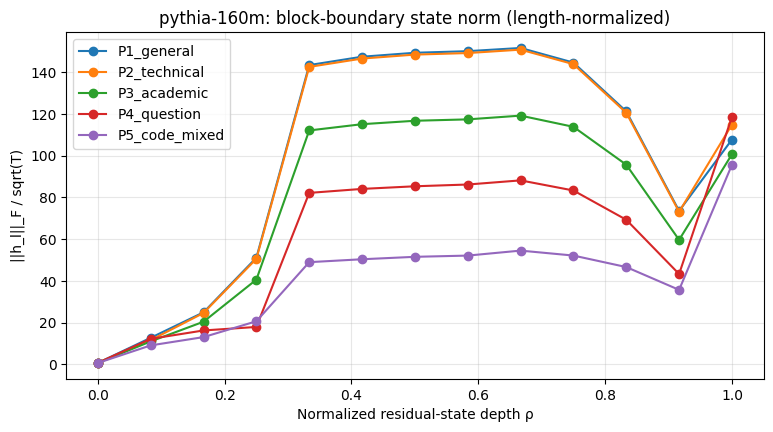

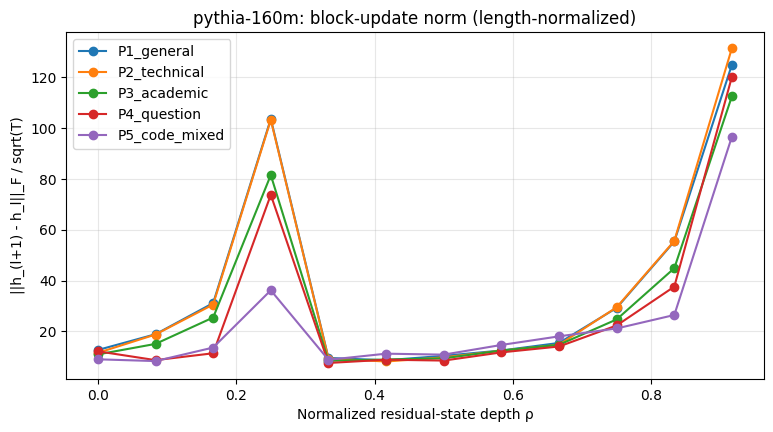

,model_key,prompt_id,n_tokens,last_block_output_norm_fro,final_norm_output_norm_fro,final_norm_output_norm_per_token_l2
0,pythia-160m,P1_general,9,323.16871,813.43047,271.14349
1,pythia-160m,P2_technical,9,344.59819,813.82488,271.27496
2,pythia-160m,P3_academic,15,389.88438,1048.39405,270.69418
3,pythia-160m,P4_question,11,393.38754,898.01893,270.76290
4,pythia-160m,P5_code_mixed,92,917.21739,2591.79427,270.21323
5,gpt2,P1_general,9,1339.97720,638.06023,212.68674
6,gpt2,P2_technical,9,1350.19296,748.87224,249.62408
7,gpt2,P3_academic,15,1560.64272,834.50708,215.46880
8,gpt2,P4_question,13,1541.14142,845.33007,234.45238
9,gpt2,P5_code_mixed,127,5214.87503,2227.05307,197.61900


In [7]:
if metrics_df.empty:
    print("No successful runs; resolve blocked loads first.")
else:
    for model_key, sub in metrics_df.groupby("model_key"):
        fig, ax = plt.subplots(figsize=(9, 4.5))
        for pid, g in sub.groupby("prompt_id"):
            ax.plot(g["rho_state"], g["hidden_norm_per_token_l2"], marker="o", label=pid)
        ax.set(title=f"{model_key}: block-boundary state norm (length-normalized)",
               xlabel="Normalized residual-state depth ρ", ylabel="||h_l||_F / sqrt(T)")
        ax.grid(True, alpha=.3); ax.legend(); plt.show()

        fig, ax = plt.subplots(figsize=(9, 4.5))
        for pid, g in sub.groupby("prompt_id"):
            g = g.dropna(subset=["block_update_norm_per_token_l2"])
            ax.plot(g["rho_state"], g["block_update_norm_per_token_l2"], marker="o", label=pid)
        ax.set(title=f"{model_key}: block-update norm (length-normalized)",
               xlabel="Normalized residual-state depth ρ", ylabel="||h_(l+1) - h_l||_F / sqrt(T)")
        ax.grid(True, alpha=.3); ax.legend(); plt.show()

    display(metadata_df[["model_key", "prompt_id", "n_tokens", "last_block_output_norm_fro",
                         "final_norm_output_norm_fro", "final_norm_output_norm_per_token_l2"]].round(5))

## 5. Inspect full measurements

In [8]:
if not metrics_df.empty:
    display(metrics_df[["model_key", "prompt_id", "style", "layer_state_idx", "rho_state",
        "n_tokens", "hidden_dim", "hidden_norm_fro", "hidden_norm_per_token_l2",
        "hidden_rms_per_element", "block_update_norm_fro_to_next",
        "block_update_norm_per_token_l2", "relative_block_update_norm"]].round(6))

,model_key,prompt_id,style,layer_state_idx,rho_state,n_tokens,hidden_dim,hidden_norm_fro,hidden_norm_per_token_l2,hidden_rms_per_element,block_update_norm_fro_to_next,block_update_norm_per_token_l2,relative_block_update_norm
0,pythia-160m,P1_general,general_prose,0,0.000000,9,768,2.206983,0.735661,0.026546,38.151377,12.717126,17.286668
1,pythia-160m,P1_general,general_prose,1,0.083333,9,768,38.357386,12.785795,0.461368,56.740355,18.913452,1.479255
2,pythia-160m,P1_general,general_prose,2,0.166667,9,768,74.935491,24.978497,0.901334,93.512386,31.170795,1.247905
3,pythia-160m,P1_general,general_prose,3,0.250000,9,768,153.422526,51.140842,1.845386,310.953071,103.651024,2.026776
4,pythia-160m,P1_general,general_prose,4,0.333333,9,768,430.180331,143.393444,5.174265,28.773220,9.591073,0.066886
...,...,...,...,...,...,...,...,...,...,...,...,...,...
125,gpt2,P5_code_mixed,code_plus_natural_language,8,0.666667,127,768,3239.099111,287.423568,10.371505,444.419576,39.435860,0.137205
126,gpt2,P5_code_mixed,code_plus_natural_language,9,0.750000,127,768,3322.442930,294.819136,10.638369,613.278611,54.419677,0.184587
127,gpt2,P5_code_mixed,code_plus_natural_language,10,0.833333,127,768,3466.577434,307.609005,11.099884,1084.902229,96.269506,0.312961
128,gpt2,P5_code_mixed,code_plus_natural_language,11,0.916667,127,768,3876.862474,344.015915,12.413605,4722.941699,419.093306,1.218238


## 6. Interpretation guardrails
- A large block update is a result to investigate, not by itself evidence of chaos, a phase transition, or a physical law.
- Raw Frobenius norm scales with sequence length; use the normalized measures for prompt comparisons.
- Final LayerNorm output is a separate operation and is not included in the block-update difference.
- GPT-2 and Pythia have different architecture/activation scales; do not interpret raw norms as physical energies.
- Five prompts are pilot-only. No significance claims or population generalizations are justified.

## 7. Export outputs and run manifest
Copy or download this folder before the Colab runtime ends.

In [9]:
OUT_DIR = Path("physllm_n02_outputs_v1_1")
OUT_DIR.mkdir(parents=True, exist_ok=True)
if not metrics_df.empty:
    metrics_df.to_csv(OUT_DIR / "n02_pilot_layer_metrics.csv", index=False)
if not metadata_df.empty:
    metadata_df.to_json(OUT_DIR / "n02_pilot_run_metadata.json", orient="records", indent=2)
if not errors_df.empty:
    errors_df.to_csv(OUT_DIR / "n02_blocked_loads.csv", index=False)
summary = {
    "notebook": "N02_residual_dynamics_v1_1_corrected.ipynb",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "models_requested": MODELS_TO_RUN,
    "models_completed": sorted(metadata_df["model_key"].unique().tolist()) if not metadata_df.empty else [],
    "completed_model_prompt_runs": int(len(metadata_df)),
    "blocked_model_loads": int(len(errors_df)),
    "state_capture": "first-block input plus each Transformer block output before final LayerNorm",
    "final_layer_norm": "recorded separately; excluded from block update norm",
    "prompt_length_normalization": "Frobenius norm divided by sqrt(T) and sqrt(T*D)",
    "interpretation": "Pilot-only descriptive measurements; not Main Evaluation evidence."
}
with open(OUT_DIR / "n02_run_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
display(summary)
print("Output folder:", OUT_DIR.resolve())

{'notebook': 'N02_residual_dynamics_v1_1_corrected.ipynb',
 'created_utc': '2026-10-11T07:52:51.205426+00:00',
 'models_requested': ['pythia-160m', 'gpt2'],
 'models_completed': ['gpt2', 'pythia-160m'],
 'completed_model_prompt_runs': 10,
 'blocked_model_loads': 0,
 'state_capture': 'first-block input plus each Transformer block output before final LayerNorm',
 'final_layer_norm': 'recorded separately; excluded from block update norm',
 'prompt_length_normalization': 'Frobenius norm divided by sqrt(T) and sqrt(T*D)',
 'interpretation': 'Pilot-only descriptive measurements; not Main Evaluation evidence.'}

Output folder: /content/physllm_n02_outputs_v1_1


In [10]:
# 마지막 세 개 block 경계의 측정값 확인
cols = [
    "model_key",
    "prompt_id",
    "layer_state_idx",
    "rho_state",
    "hidden_norm_fro",
    "hidden_norm_per_token_l2",
    "block_update_norm_fro_to_next",
    "block_update_norm_per_token_l2",
]

last_rows = (
    metrics_df.sort_values(["model_key", "prompt_id", "layer_state_idx"])
    .groupby(["model_key", "prompt_id"], group_keys=False)
    .tail(3)
)

display(last_rows[cols].round(4))

# 마지막 block 출력과 LayerNorm 출력의 차이
comparison = metadata_df[
    [
        "model_key",
        "prompt_id",
        "last_block_output_norm_fro",
        "final_norm_output_norm_fro",
        "final_norm_output_norm_per_token_l2",
    ]
].copy()

comparison["final_to_block_norm_ratio"] = (
    comparison["final_norm_output_norm_fro"]
    / comparison["last_block_output_norm_fro"]
)

display(comparison.round(4))

,model_key,prompt_id,layer_state_idx,rho_state,hidden_norm_fro,hidden_norm_per_token_l2,block_update_norm_fro_to_next,block_update_norm_per_token_l2
75,gpt2,P1_general,10,0.8333,3146.2755,1048.7585,331.5412,110.5137
76,gpt2,P1_general,11,0.9167,3196.9788,1065.6596,2868.0692,956.0231
77,gpt2,P1_general,12,1.0000,1339.9772,446.6591,NaN,NaN
88,gpt2,P2_technical,10,0.8333,3147.1440,1049.0480,340.6481,113.5494
89,gpt2,P2_technical,11,0.9167,3200.4222,1066.8074,2871.9471,957.3157
90,gpt2,P2_technical,12,1.0000,1350.1930,450.0643,NaN,NaN
101,gpt2,P3_academic,10,0.8333,3142.8494,811.4802,389.2389,100.5011
102,gpt2,P3_academic,11,0.9167,3214.7514,830.0453,2908.9247,751.0811
103,gpt2,P3_academic,12,1.0000,1560.6427,402.9562,NaN,NaN
114,gpt2,P4_question,10,0.8333,3128.2558,867.6220,393.2575,109.0700


,model_key,prompt_id,last_block_output_norm_fro,final_norm_output_norm_fro,final_norm_output_norm_per_token_l2,final_to_block_norm_ratio
0,pythia-160m,P1_general,323.1687,813.4305,271.1435,2.5170
1,pythia-160m,P2_technical,344.5982,813.8249,271.2750,2.3617
2,pythia-160m,P3_academic,389.8844,1048.3941,270.6942,2.6890
3,pythia-160m,P4_question,393.3875,898.0189,270.7629,2.2828
4,pythia-160m,P5_code_mixed,917.2174,2591.7943,270.2132,2.8257
5,gpt2,P1_general,1339.9772,638.0602,212.6867,0.4762
6,gpt2,P2_technical,1350.1930,748.8722,249.6241,0.5546
7,gpt2,P3_academic,1560.6427,834.5071,215.4688,0.5347
8,gpt2,P4_question,1541.1414,845.3301,234.4524,0.5485
9,gpt2,P5_code_mixed,5214.8750,2227.0531,197.6190,0.4271


GPT-2의 일반 문장에서는 마지막 block의 업데이트 Norm이 직전 block보다 약 7.4~8.7배 커. 그런데 출력 상태의 Norm은 이전 상태의 약 42~49%로 감소했어.
이는 마지막 block이 단순히 표현 크기를 키우는 것이 아니라, 큰 업데이트를 적용하면서 전체 상태 Norm은 낮추는 방향으로 작동할 수 있음을 보여줘. 다만 Norm만으로는 방향 변화와 상쇄의 정확한 원인을 알 수 없어.
Pythia에서는 마지막 block 업데이트도 직전 업데이트보다 컸지만, 출력 상태 Norm은 증가했어. 두 모델이 마지막 block에서 서로 다른 동역학적 패턴을 보인다는 가설을 세울 만한 결과임

마지막 block의 Attention과 MLP를 분해하자
Transformer block의 출력은 잔차 입력과 Attention·MLP 가지(branch)의 출력으로 구성돼. 이제 이 항들을 직접 측정하면 큰 업데이트가 어느 가지에서 비롯되는지 확인할 수 있어.
새 셀에 아래 코드를 실행해. 수정된 N02 노트북의 load_causal_lm, resolve_block_and_final_norm, MODEL_IDS, PROMPTS, DTYPE 정의를 사용하는 코드야.

In [11]:
MODELS_TO_RUN = ["gpt2", "pythia-160m"]

print("실험 대상 모델:", MODELS_TO_RUN)
print("설정 완료")

실험 대상 모델: ['gpt2', 'pythia-160m']
설정 완료


In [12]:
# N02 — 모델 설정 통합 복구 셀

MODEL_IDS = {
    "gpt2": "gpt2",
    "pythia-160m": "EleutherAI/pythia-160m",
}

MODELS_TO_RUN = [
    "gpt2",
    "pythia-160m",
]

print("MODEL_IDS =", MODEL_IDS)
print("MODELS_TO_RUN =", MODELS_TO_RUN)
print("설정 확인:", set(MODELS_TO_RUN).issubset(MODEL_IDS))


MODEL_IDS = {'gpt2': 'gpt2', 'pythia-160m': 'EleutherAI/pythia-160m'}
MODELS_TO_RUN = ['gpt2', 'pythia-160m']
설정 확인: True


In [13]:
# ============================================================
# PhysLLM N02 — Self-contained final-block branch diagnostic
# GPT-2 + Pythia-160M
# ============================================================

import gc
import torch
import pandas as pd
import transformers

from IPython.display import display

# 1. 모든 설정을 이 셀 안에서 정의
MODEL_IDS = {
    "gpt2": "gpt2",
    "pythia-160m": "EleutherAI/pythia-160m",
}

MODELS_TO_RUN = ["gpt2", "pythia-160m"]
DTYPE = torch.float32
MAX_LENGTH = 512

PROMPTS = [
    {
        "prompt_id": "P1_general",
        "text": "The small bird flew across the quiet garden.",
    },
    {
        "prompt_id": "P2_technical",
        "text": "The system records information from several independent sensors.",
    },
    {
        "prompt_id": "P3_academic",
        "text": "Physics-guided machine learning provides interpretable representations of deep neural networks.",
    },
    {
        "prompt_id": "P4_question",
        "text": "Could you please explain how quantum entanglement violates local realism?",
    },
    {
        "prompt_id": "P5_code_mixed",
        "text": '''def bubble_sort(arr):
    n = len(arr)
    for i in range(n - 1):
        for j in range(n - i - 1):
            if arr[j] > arr[j + 1]:
                arr[j], arr[j + 1] = arr[j + 1], arr[j]
    return arr

# Explain the time complexity of this function.''',
    },
]

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA:", torch.cuda.is_available())
print("Models:", MODEL_IDS)


# 2. 모델 로딩
def load_causal_lm(model_id, dtype):
    tokenizer = transformers.AutoTokenizer.from_pretrained(model_id)

    model = transformers.AutoModelForCausalLM.from_pretrained(
        model_id,
        torch_dtype=dtype,
        low_cpu_mem_usage=True,
    )

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
    model.to(device)
    model.eval()

    return tokenizer, model, device


# 3. 아키텍처별 마지막 Transformer block 찾기
def resolve_last_block(model):
    if hasattr(model, "transformer") and hasattr(model.transformer, "h"):
        return model.transformer.h[-1], "gpt2"

    if hasattr(model, "gpt_neox") and hasattr(model.gpt_neox, "layers"):
        return model.gpt_neox.layers[-1], "gpt_neox_pythia"

    raise RuntimeError(
        "지원하지 않는 구조입니다. GPT-2/Pythia 모델인지 확인하세요."
    )


# 4. 모듈 출력에서 첫 번째 텐서 추출
def first_tensor(output):
    if isinstance(output, torch.Tensor):
        return output

    if isinstance(output, (tuple, list)):
        for item in output:
            if isinstance(item, torch.Tensor):
                return item

    raise TypeError(
        f"출력에서 Tensor를 찾을 수 없습니다: {type(output)}"
    )


# 5. 마지막 block의 Attention·MLP 분해
@torch.inference_mode()
def diagnose_final_block(tokenizer, model, device, prompt):

    block, architecture = resolve_last_block(model)

    if architecture == "gpt2":
        attention_module = block.attn
    else:
        attention_module = block.attention

    captured = {}
    handles = []

    def block_pre_hook(module, args):
        if not args or not isinstance(args[0], torch.Tensor):
            raise RuntimeError("마지막 block 입력 캡처 실패")
        captured["input"] = args[0].detach()

    def block_post_hook(module, args, output):
        captured["output"] = first_tensor(output).detach()

    def attention_hook(module, args, output):
        captured["attention"] = first_tensor(output).detach()

    def mlp_hook(module, args, output):
        captured["mlp"] = first_tensor(output).detach()

    handles.append(
        block.register_forward_pre_hook(block_pre_hook)
    )
    handles.append(
        block.register_forward_hook(block_post_hook)
    )
    handles.append(
        attention_module.register_forward_hook(attention_hook)
    )
    handles.append(
        block.mlp.register_forward_hook(mlp_hook)
    )

    try:
        encoded = tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=MAX_LENGTH,
        )
        encoded = {k: v.to(device) for k, v in encoded.items()}

        outputs = model(
            **encoded,
            use_cache=False,
        )

    finally:
        # 오류가 발생하더라도 hook을 반드시 제거
        for handle in handles:
            handle.remove()

    required = ["input", "output", "attention", "mlp"]
    missing = [key for key in required if key not in captured]

    if missing:
        raise RuntimeError(f"캡처되지 않은 텐서: {missing}")

    # 배치 차원 제거, 계산은 float64로 통일
    x, y, attn, mlp = [
        captured[k][0].detach().to("cpu", dtype=torch.float64)
        for k in required
    ]

    if not all(torch.isfinite(t).all() for t in [x, y, attn, mlp]):
        raise FloatingPointError("NaN/Inf 발견")

    delta = y - x
    branch_sum = attn + mlp
    error = delta - branch_sum

    def norm(t):
        return torch.linalg.vector_norm(t).item()

    n_attn = norm(attn)
    n_mlp = norm(mlp)

    cosine = (
        torch.sum(attn * mlp).item() / (n_attn * n_mlp)
        if n_attn > 0 and n_mlp > 0
        else float("nan")
    )

    input_norm = norm(x)
    output_norm = norm(y)
    delta_norm = norm(delta)
    n_tokens = int(x.shape[0])

    return {
        "n_tokens": n_tokens,
        "input_norm": input_norm,
        "attention_branch_norm": n_attn,
        "mlp_branch_norm": n_mlp,
        "attention_mlp_cosine": cosine,
        "actual_update_norm": delta_norm,
        "branch_sum_norm": norm(branch_sum),
        "update_relative_norm": delta_norm / max(input_norm, 1e-12),
        "output_norm": output_norm,
        "output_input_norm_ratio": output_norm / max(input_norm, 1e-12),
        "reconstruction_mae": error.abs().mean().item(),
        "reconstruction_max_abs": error.abs().max().item(),
    }


# 6. 실행
results = []
errors = []

for model_key in MODELS_TO_RUN:
    model_id = MODEL_IDS[model_key]
    print(f"\n{'=' * 55}")
    print("Loading:", model_id)

    tokenizer = model = None

    try:
        tokenizer, model, device = load_causal_lm(model_id, DTYPE)
        print("Loaded on:", device)

        for p in PROMPTS:
            print("Diagnosing:", model_key, p["prompt_id"])

            try:
                row = diagnose_final_block(
                    tokenizer,
                    model,
                    device,
                    p["text"],
                )

                row["model_key"] = model_key
                row["prompt_id"] = p["prompt_id"]
                results.append(row)

            except Exception as exc:
                errors.append({
                    "model_key": model_key,
                    "prompt_id": p["prompt_id"],
                    "error": repr(exc),
                })
                print("DIAGNOSTIC ERROR:", repr(exc))

    except Exception as exc:
        errors.append({
            "model_key": model_key,
            "prompt_id": "ALL",
            "error": repr(exc),
        })
        print("MODEL LOAD ERROR:", repr(exc))

    finally:
        if model is not None:
            del model
        if tokenizer is not None:
            del tokenizer

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# 7. 결과 및 재구성 검증
branch_df = pd.DataFrame(results)
error_df = pd.DataFrame(errors)

if not branch_df.empty:
    cols = [
        "model_key",
        "prompt_id",
        "n_tokens",
        "input_norm",
        "attention_branch_norm",
        "mlp_branch_norm",
        "attention_mlp_cosine",
        "actual_update_norm",
        "output_norm",
        "output_input_norm_ratio",
        "reconstruction_mae",
        "reconstruction_max_abs",
    ]

    display(branch_df[cols].round(6))

    print("\n재구성 오차 요약:")
    display(
        branch_df.groupby("model_key")[
            ["reconstruction_mae", "reconstruction_max_abs"]
        ].max().round(10)
    )
else:
    print("성공한 진단 결과가 없습니다.")

if not error_df.empty:
    print("\n오류 발생 목록:")
    display(error_df)


PyTorch: 2.11.0+cpu
Transformers: 5.19.0
CUDA: False
Models: {'gpt2': 'gpt2', 'pythia-160m': 'EleutherAI/pythia-160m'}

Loading: gpt2


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loaded on: cpu
Diagnosing: gpt2 P1_general
Diagnosing: gpt2 P2_technical
Diagnosing: gpt2 P3_academic
Diagnosing: gpt2 P4_question
Diagnosing: gpt2 P5_code_mixed

Loading: EleutherAI/pythia-160m


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loaded on: cpu
Diagnosing: pythia-160m P1_general
Diagnosing: pythia-160m P2_technical
Diagnosing: pythia-160m P3_academic
Diagnosing: pythia-160m P4_question
Diagnosing: pythia-160m P5_code_mixed


,model_key,prompt_id,n_tokens,input_norm,attention_branch_norm,mlp_branch_norm,attention_mlp_cosine,actual_update_norm,output_norm,output_input_norm_ratio,reconstruction_mae,reconstruction_max_abs
0,gpt2,P1_general,9,3196.978751,2717.871539,357.245145,0.366329,2868.069209,1339.977195,0.419139,0.0,0.000015
1,gpt2,P2_technical,9,3200.422216,2726.624997,347.067305,0.366229,2871.947087,1350.192958,0.421880,0.0,0.000014
2,gpt2,P3_academic,15,3214.751433,2738.919383,379.905224,0.392029,2908.924705,1560.642723,0.485463,0.0,0.000015
3,gpt2,P4_question,13,3192.754030,2731.692744,404.560604,0.373805,2907.236696,1541.141421,0.482700,0.0,0.000014
4,gpt2,P5_code_mixed,127,3876.862474,3967.208576,1371.639783,0.430577,4722.941699,5214.875032,1.345128,0.0,0.000023
5,pythia-160m,P1_general,9,220.664754,58.622332,330.531355,0.722790,375.097151,323.168713,1.464523,0.0,0.000001
6,pythia-160m,P2_technical,9,219.339946,57.949264,348.994174,0.757005,394.682554,344.598194,1.571069,0.0,0.000003
7,pythia-160m,P3_academic,15,231.167487,77.501600,374.362951,0.758571,436.087229,389.884383,1.686588,0.0,0.000005
8,pythia-160m,P4_question,11,143.711016,61.915809,343.571650,0.875682,398.912215,393.387542,2.737351,0.0,0.000003
9,pythia-160m,P5_code_mixed,92,342.791720,186.495620,759.778447,0.876535,927.602118,917.217389,2.675728,0.0,0.000004



재구성 오차 요약:


,reconstruction_mae,reconstruction_max_abs
model_key,,
gpt2,1.815000e-07,0.000023
pythia-160m,1.248000e-07,0.000005


In [14]:
import torch
import pandas as pd

def first_tensor(output):
    return output[0] if isinstance(output, (tuple, list)) else output


@torch.inference_mode()
def diagnose_final_block(tokenizer, model, device, prompt):
    blocks, _, architecture = resolve_block_and_final_norm(model)
    block = blocks[-1]

    if architecture == "gpt2":
        attention_module = block.attn
    elif architecture == "gpt_neox_pythia":
        attention_module = block.attention
    else:
        raise RuntimeError(f"Unsupported architecture: {architecture}")

    captured = {}
    handles = []

    def block_pre_hook(module, args):
        captured["input"] = args[0].detach()

    def block_post_hook(module, args, output):
        captured["output"] = first_tensor(output).detach()

    def branch_hook(name):
        def hook(module, args, output):
            captured[name] = first_tensor(output).detach()
        return hook

    handles.append(block.register_forward_pre_hook(block_pre_hook))
    handles.append(block.register_forward_hook(block_post_hook))
    handles.append(
        attention_module.register_forward_hook(branch_hook("attention"))
    )
    handles.append(block.mlp.register_forward_hook(branch_hook("mlp")))

    try:
        encoded = tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=512,
        )
        encoded = {k: v.to(device) for k, v in encoded.items()}
        model(**encoded, use_cache=False)
    finally:
        for handle in handles:
            handle.remove()

    required = ["input", "output", "attention", "mlp"]
    missing = [key for key in required if key not in captured]
    if missing:
        raise RuntimeError(f"Missing hook captures: {missing}")

    x, y, a, m = [
        captured[k][0].detach().to("cpu", dtype=torch.float64)
        for k in required
    ]

    delta = y - x
    reconstructed_delta = a + m
    eps = 1e-12

    def norm(t):
        return torch.linalg.vector_norm(t).item()

    cosine = torch.sum(a * m).item() / max(norm(a) * norm(m), eps)
    error = delta - reconstructed_delta

    return {
        "architecture": architecture,
        "n_tokens": int(x.shape[0]),
        "input_norm": norm(x),
        "attention_branch_norm": norm(a),
        "mlp_branch_norm": norm(m),
        "attention_mlp_cosine": cosine,
        "actual_update_norm": norm(delta),
        "reconstructed_update_norm": norm(reconstructed_delta),
        "reconstruction_mae": error.abs().mean().item(),
        "reconstruction_max_abs": error.abs().max().item(),
        "output_norm": norm(y),
        "output_input_norm_ratio": norm(y) / max(norm(x), eps),
    }


results = []

for model_key in ["gpt2", "pythia-160m"]:
    tokenizer, model, device = load_causal_lm(
        MODEL_IDS[model_key], torch.float32
    )

    try:
        for p in PROMPTS:
            row = diagnose_final_block(
                tokenizer, model, device, p["text"]
            )
            row.update({
                "model_key": model_key,
                "prompt_id": p["prompt_id"],
            })
            results.append(row)
    finally:
        del tokenizer, model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

branch_df = pd.DataFrame(results)
display(branch_df.round(6))

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

,architecture,n_tokens,input_norm,attention_branch_norm,mlp_branch_norm,attention_mlp_cosine,actual_update_norm,reconstructed_update_norm,reconstruction_mae,reconstruction_max_abs,output_norm,output_input_norm_ratio,model_key,prompt_id
0,gpt2,9,3196.978751,2717.871539,357.245145,0.366329,2868.069209,2868.069207,0.0,0.000015,1339.977195,0.419139,gpt2,P1_general
1,gpt2,9,3200.422216,2726.624997,347.067305,0.366229,2871.947087,2871.947088,0.0,0.000014,1350.192958,0.421880,gpt2,P2_technical
2,gpt2,15,3214.751433,2738.919383,379.905224,0.392029,2908.924705,2908.924715,0.0,0.000015,1560.642723,0.485463,gpt2,P3_academic
3,gpt2,13,3192.754030,2731.692744,404.560604,0.373805,2907.236696,2907.236699,0.0,0.000014,1541.141421,0.482700,gpt2,P4_question
4,gpt2,127,3876.862474,3967.208576,1371.639783,0.430577,4722.941699,4722.941707,0.0,0.000023,5214.875032,1.345128,gpt2,P5_code_mixed
5,gpt_neox_pythia,9,220.664754,58.622332,330.531355,0.722790,375.097151,375.097151,0.0,0.000001,323.168713,1.464523,pythia-160m,P1_general
6,gpt_neox_pythia,9,219.339946,57.949264,348.994174,0.757005,394.682554,394.682554,0.0,0.000003,344.598194,1.571069,pythia-160m,P2_technical
7,gpt_neox_pythia,15,231.167487,77.501600,374.362951,0.758571,436.087229,436.087230,0.0,0.000005,389.884383,1.686588,pythia-160m,P3_academic
8,gpt_neox_pythia,11,143.711016,61.915809,343.571650,0.875682,398.912215,398.912215,0.0,0.000003,393.387542,2.737351,pythia-160m,P4_question
9,gpt_neox_pythia,92,342.791720,186.495620,759.778447,0.876535,927.602118,927.602118,0.0,0.000004,917.217389,2.675728,pythia-160m,P5_code_mixed


### 9. 본 평가(Main Evaluation) 진입 전 최종 분석: Attention vs MLP 기여도
마지막 블록에서 발생하는 큰 업데이트가 Attention과 MLP 중 어느 가지(branch)에서 주로 비롯되는지 시각적으로 비교 분석합니다. 이 분석 결과는 본 평가 데이터셋 및 가설 검증의 중요한 설계 기준선이 됩니다.

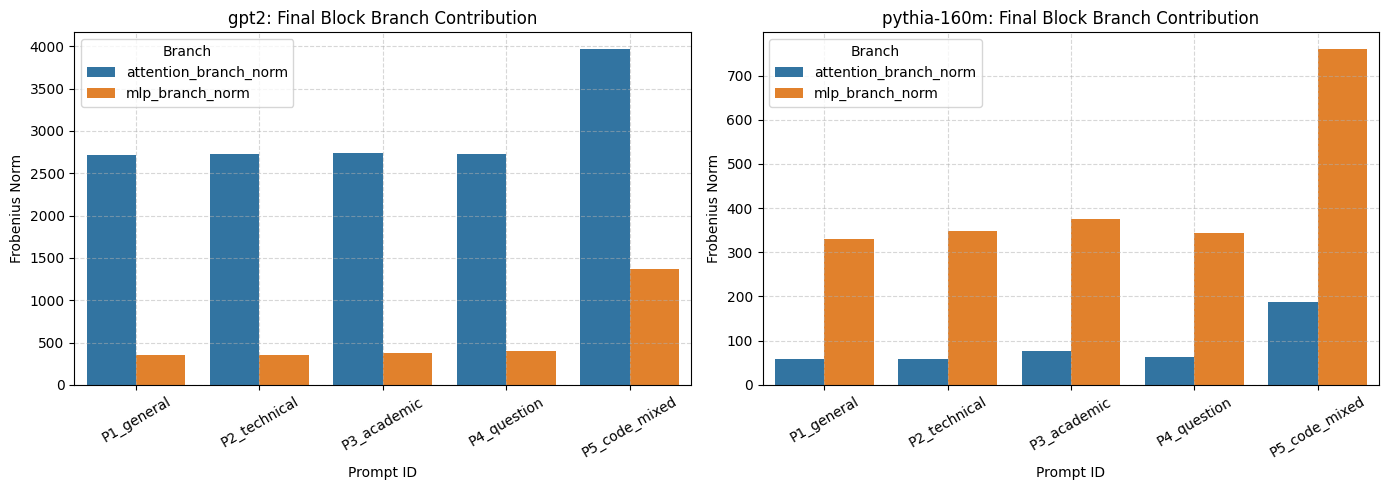

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

if not branch_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

    for idx, model_key in enumerate(["gpt2", "pythia-160m"]):
        sub_df = branch_df[branch_df["model_key"] == model_key]
        ax = axes[idx]

        # Melt for visualization
        melted = sub_df.melt(
            id_vars=["prompt_id"],
            value_vars=["attention_branch_norm", "mlp_branch_norm"],
            var_name="Branch",
            value_name="Norm"
        )

        sns.barplot(x="prompt_id", y="Norm", hue="Branch", data=melted, ax=ax)
        ax.set_title(f"{model_key}: Final Block Branch Contribution")
        ax.set_xlabel("Prompt ID")
        ax.set_ylabel("Frobenius Norm")
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.tick_params(axis='x', rotation=30)

    plt.tight_layout()
    plt.show()
else:
    print("branch_df가 비어 있어 그래프를 그릴 수 없습니다.")

## 8. N02 pilot checklist
- [ ] Checkpoint loads recorded; blocked runs not counted as passes.
- [ ] Number of block-boundary states equals `n_blocks + 1`.
- [ ] All block outputs and final LayerNorm output were captured separately.
- [ ] No NaN/Inf in states, final LayerNorm output, or logits.
- [ ] Prompt-length-normalized plots inspected.
- [ ] CSV and JSON metadata exported.

**Gate status: INCONCLUSIVE until the corrected run is reviewed.** This notebook does not by itself establish a physics hypothesis or generalization.